# 1. Thu thập và đọc dữ liệu


In [16]:
import pandas as pd
from pyspark.sql import SparkSession
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.classification import GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator, MulticlassClassificationEvaluator
import seaborn as sns
import matplotlib.pyplot as plt

spark = SparkSession.builder.appName("GBT_Classifier").getOrCreate()
df = spark.read.parquet("/Users/mac/Downloads/Graph_Analytics_For_Discovering_Emerging_Influential_Papers/data/processed/citation_ml_dataset.parquet")


# 2. Thống kê dữ liệu


In [17]:
print("Số lượng dòng:", df.count())
print("Số lượng cột:", len(df.columns))
df.printSchema()


Số lượng dòng: 694450
Số lượng cột: 13
root
 |-- paper_id: long (nullable = true)
 |-- pub_year: long (nullable = true)
 |-- past_in_degree: long (nullable = true)
 |-- num_authors: long (nullable = true)
 |-- num_topics: long (nullable = true)
 |-- pagerank_score: double (nullable = true)
 |-- paper_age: long (nullable = true)
 |-- citation_velocity: double (nullable = true)
 |-- paper_feat_128d: vector (nullable = true)
 |-- delta_c: long (nullable = true)
 |-- ogb_split: string (nullable = true)
 |-- label: double (nullable = true)
 |-- temporal_split: string (nullable = true)



# 3. Trực quan hóa dữ liệu


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/var/folders/bj/4zbr51sj4fsbvtllcchl3wzc0000gn/T/ipykernel_13494/3789449976.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="label", y="count", data=label_counts, palette=["blue", "red"])


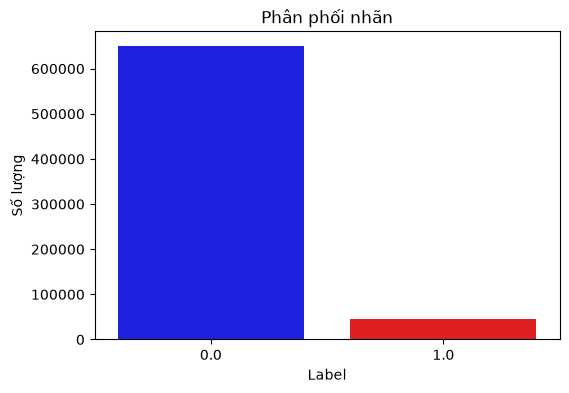

   label   count
0    0.0  649837
1    1.0   44613


In [18]:
label_counts = df.groupBy("label").count().toPandas()
plt.figure(figsize=(6, 4))
sns.barplot(x="label", y="count", data=label_counts, palette=["blue", "red"])
plt.title("Phân phối nhãn")
plt.xlabel("Label")
plt.ylabel("Số lượng")
plt.show()
print(label_counts)


# 4. Tiền xử lý dữ liệu và chia tập dữ liệu


In [19]:
features = ["citation_velocity", "pagerank_score", "paper_age"]
target = "label"

assembler = VectorAssembler(inputCols=features, outputCol="raw_features")
assembled_df = assembler.transform(df)

train_data = assembled_df.filter(assembled_df["temporal_split"] == "train")
val_data = assembled_df.filter(assembled_df["temporal_split"] == "valid")
test_data = assembled_df.filter(assembled_df["temporal_split"] == "test")

print("Train:", train_data.count())
print("Validation:", val_data.count())
print("Test:", test_data.count())

scaler = StandardScaler(inputCol="raw_features", outputCol="scaled_features", withMean=True, withStd=True)
scaler_model = scaler.fit(train_data)

train_scaled = scaler_model.transform(train_data)
val_scaled = scaler_model.transform(val_data)
test_scaled = scaler_model.transform(test_data)


Train: 559373
Validation: 70198
Test: 64879


In [20]:
# Tăng cường dữ liệu
majority_df = train_scaled.filter("label = 0.0")
minority_df = train_scaled.filter("label = 1.0")

# Tính tỷ lệ cần tăng
ratio = majority_df.count() / minority_df.count()

# Tăng mẫu lớp thiểu số
oversampled = minority_df.sample(
    withReplacement=True,
    fraction=ratio - 1,
    seed=42
)

# Gộp dữ liệu
train_balanced = majority_df.union(minority_df).union(oversampled)

print("Majority:", majority_df.count())
print("Minority:", minority_df.count())

Majority: 530361
Minority: 29012


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/var/folders/bj/4zbr51sj4fsbvtllcchl3wzc0000gn/T/ipykernel_13494/1893273948.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="label", y="count", data=label_counts, palette=["blue", "red"])


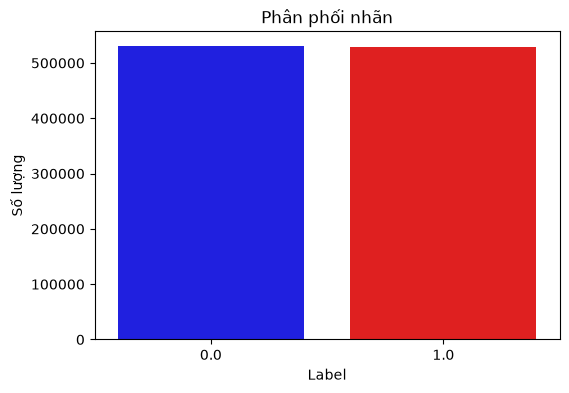

   label   count
0    0.0  530361
1    1.0  529604


In [21]:
label_counts = train_balanced.groupBy("label").count().toPandas()
plt.figure(figsize=(6, 4))
sns.barplot(x="label", y="count", data=label_counts, palette=["blue", "red"])
plt.title("Phân phối nhãn")
plt.xlabel("Label")
plt.ylabel("Số lượng")
plt.show()
print(label_counts)

# 5. Model Training (Huấn luyện mô hình)


In [22]:
gbt = GBTClassifier(featuresCol="scaled_features", labelCol=target, maxIter=20, seed=42)
gbt_model = gbt.fit(train_balanced)

print("Feature Importances:", gbt_model.featureImportances)


Feature Importances: (3,[0,1,2],[0.963877525932469,0.0184377496991873,0.017684724368343657])


# 6. Model Validation (Kiểm định trên tập Validation)


In [23]:
val_predictions = gbt_model.transform(val_scaled)

pr_evaluator = BinaryClassificationEvaluator(labelCol=target, rawPredictionCol="rawPrediction", metricName="areaUnderPR")
roc_evaluator = BinaryClassificationEvaluator(labelCol=target, rawPredictionCol="rawPrediction", metricName="areaUnderROC")
f1_evaluator = MulticlassClassificationEvaluator(labelCol=target, predictionCol="prediction", metricName="f1")

print("Validation PR-AUC:", pr_evaluator.evaluate(val_predictions))
print("Validation ROC-AUC:", roc_evaluator.evaluate(val_predictions))
print("Validation F1-Score:", f1_evaluator.evaluate(val_predictions))


Validation PR-AUC: 0.6590368897771922
Validation ROC-AUC: 0.9131496285590978
Validation F1-Score: 0.8484370953929238


# 7. Model Testing (Đánh giá trên tập Test)


In [24]:
test_predictions = gbt_model.transform(test_scaled)

print("Test PR-AUC:", pr_evaluator.evaluate(test_predictions))
print("Test ROC-AUC:", roc_evaluator.evaluate(test_predictions))
print("Test F1-Score:", f1_evaluator.evaluate(test_predictions))


Test PR-AUC: 0.5287643841253722
Test ROC-AUC: 0.7867993638910593
Test F1-Score: 0.8560421126421176


In [25]:
test_predictions.select("paper_id", "label", "prediction", "rawPrediction").show(10, truncate=False)


+--------+-----+----------+------------------------------------------+
|paper_id|label|prediction|rawPrediction                             |
+--------+-----+----------+------------------------------------------+
|3383    |0.0  |0.0       |[1.3983286159012611,-1.3983286159012611]  |
|9588    |0.0  |0.0       |[1.3983286159012611,-1.3983286159012611]  |
|10024   |0.0  |0.0       |[0.3901036709187682,-0.3901036709187682]  |
|87870   |1.0  |1.0       |[-1.518556035530061,1.518556035530061]    |
|455608  |1.0  |1.0       |[-1.4281468389062513,1.4281468389062513]  |
|456269  |0.0  |0.0       |[1.3983286159012611,-1.3983286159012611]  |
|466691  |0.0  |1.0       |[-0.42440942091831024,0.42440942091831024]|
|472841  |0.0  |0.0       |[0.13554816143135212,-0.13554816143135212]|
|478300  |0.0  |0.0       |[1.3983286159012611,-1.3983286159012611]  |
|493006  |0.0  |1.0       |[-0.7607008838007958,0.7607008838007958]  |
+--------+-----+----------+------------------------------------------+
only s

In [26]:
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

# 1. Accuracy
acc_eval = MulticlassClassificationEvaluator(labelCol=target, predictionCol="prediction", metricName="accuracy")

# 2. Precision, Recall, F1 riêng cho nhãn 1 (metricLabel=1.0)
prec1_eval = MulticlassClassificationEvaluator(labelCol=target, predictionCol="prediction", metricName="precisionByLabel", metricLabel=1.0)
rec1_eval = MulticlassClassificationEvaluator(labelCol=target, predictionCol="prediction", metricName="recallByLabel", metricLabel=1.0)
f1_1_eval = MulticlassClassificationEvaluator(labelCol=target, predictionCol="prediction", metricName="f1", metricLabel=1.0)

# 3. Precision, Recall, F1 riêng cho nhãn 1 (metricLabel=0)
prec0_eval = MulticlassClassificationEvaluator(labelCol=target, predictionCol="prediction", metricName="precisionByLabel", metricLabel=0.0)
rec0_eval = MulticlassClassificationEvaluator(labelCol=target, predictionCol="prediction", metricName="recallByLabel", metricLabel=0.0)
f1_0_eval = MulticlassClassificationEvaluator(labelCol=target, predictionCol="prediction", metricName="f1", metricLabel=0.0)

print(f"Test Accuracy:          {acc_eval.evaluate(test_predictions):.4f}")
print(f"Test Precision (Lớp 1): {prec1_eval.evaluate(test_predictions):.4f}")
print(f"Test Recall (Lớp 1):    {rec1_eval.evaluate(test_predictions):.4f}")
print(f"Test F1-Score (Lớp 1):  {f1_1_eval.evaluate(test_predictions):.4f}")


print(f"Test Accuracy:          {acc_eval.evaluate(test_predictions):.4f}")
print(f"Test Precision (Lớp 0): {prec0_eval.evaluate(test_predictions):.4f}")
print(f"Test Recall (Lớp 0):    {rec0_eval.evaluate(test_predictions):.4f}")
print(f"Test F1-Score (Lớp 0):  {f1_0_eval.evaluate(test_predictions):.4f}")

print(f"Test F1-Score (Weighted): {f1_evaluator.evaluate(test_predictions):.4f}")

Test Accuracy:          0.8494
Test Precision (Lớp 1): 0.4559
Test Recall (Lớp 1):    0.5660
Test F1-Score (Lớp 1):  0.8560
Test Accuracy:          0.8494
Test Precision (Lớp 0): 0.9291
Test Recall (Lớp 0):    0.8939
Test F1-Score (Lớp 0):  0.8560
Test F1-Score (Weighted): 0.8560


# 8. Trích xuất kết quả dự đoán


In [27]:
from sklearn.metrics import confusion_matrix, precision_recall_curve, roc_curve, auc

pred_pd = test_predictions.select("label", "prediction", "rawPrediction").toPandas()
y_true = pred_pd["label"].values
y_pred = pred_pd["prediction"].values
y_score = pred_pd["rawPrediction"].apply(lambda v: float(v[1])).values


/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


# 9. Biểu đồ 1: Confusion Matrix


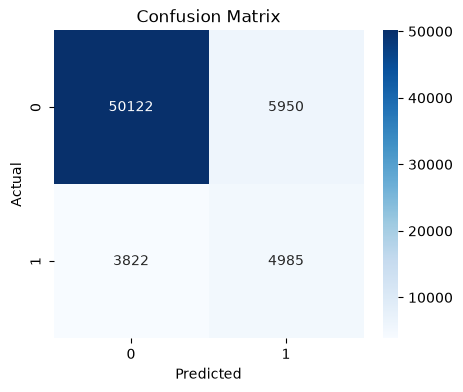

In [28]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["0", "1"], yticklabels=["0", "1"])
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# 10. Biểu đồ 2: Precision-Recall Curve


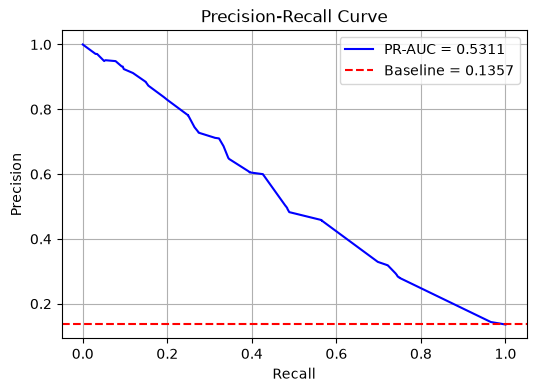

In [29]:
precision, recall, _ = precision_recall_curve(y_true, y_score)
pr_auc_val = auc(recall, precision)

plt.figure(figsize=(6, 4))
plt.plot(recall, precision, color="blue", label=f"PR-AUC = {pr_auc_val:.4f}")
plt.axhline(y=y_true.mean(), color="red", linestyle="--", label=f"Baseline = {y_true.mean():.4f}")
plt.title("Precision-Recall Curve")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.grid(True)
plt.show()


# 11. Biểu đồ 3: ROC-AUC Curve


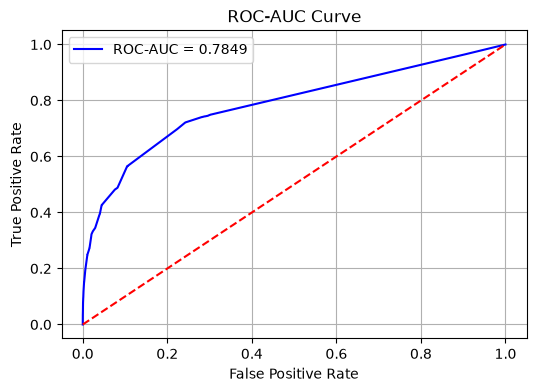

In [30]:
fpr, tpr, _ = roc_curve(y_true, y_score)
roc_auc_val = auc(fpr, tpr)

plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, color="blue", label=f"ROC-AUC = {roc_auc_val:.4f}")
plt.plot([0, 1], [0, 1], color="red", linestyle="--")
plt.title("ROC-AUC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.show()


In [31]:
spark.stop()